In [1]:
# Imports (todos nesta célula)
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score)

# A preparação escolhida nas tarefas 2 e 3 e a régua de avaliação estão em preprocessing.py,
# o mesmo ficheiro que o 02_preprocessing importa (como o preprocessing.py das práticas)
from preprocessing import (ENCODER_FINAL, SCALER_FINAL, TARGET, compare, evaluate, fit_predict,
                           load_train, prepare_selected, sem, time_splits, verdict)

In [2]:
# ===== [4.0] FERRAMENTAS - início =====
# Passo 1 - os dados e as 5 divisões por tempo, exatamente como no 02 (passos 1 a 3): o treino
# ordenado por data, sem as 65 linhas sem data, e cada divisão treina no passado e valida no
# que vem a seguir (W5, secção 3.4)
raw, frame = load_train("../data/train.csv")
splits = time_splits(frame)
test_csv = pd.read_csv("../data/test.csv", index_col="ID")

print(f"treino: {len(frame):,} compras ({len(raw) - len(frame)} sem data ficam de fora);"
      f" teste: {len(test_csv):,} compras")
for fold, (train_idx, val_idx) in enumerate(splits, start=1):
    print(f"divisão {fold}: treina com {len(train_idx):,}, valida com {len(val_idx):,}")

treino: 6,469 compras (65 sem data ficam de fora); teste: 986 compras
divisão 1: treina com 1,079, valida com 1,078
divisão 2: treina com 2,157, valida com 1,078
divisão 3: treina com 3,235, valida com 1,078
divisão 4: treina com 4,313, valida com 1,078
divisão 5: treina com 5,391, valida com 1,078


In [3]:
# Passo 2 - verificação: a preparação importada tem de dar o resultado do 02 (passo 62: F1
# 0.7508, accuracy 0.7163). Se o preprocessing.py mudar sem querer, o notebook pára aqui com um
# erro. A tolerância de 0.001 é para outro computador, onde a 4.ª casa decimal pode mudar.
selected_run = evaluate(prepare_selected, frame, splits, scaler=SCALER_FINAL,
                        encoder=ENCODER_FINAL)
assert abs(selected_run["f1"].mean() - 0.7508) < 0.001
assert abs(selected_run["accuracy"].mean() - 0.7163) < 0.001
print(f"referência (regressão logística, preparação final): F1 {selected_run['f1'].mean():.4f}"
      f" +- {sem(selected_run['f1']):.4f}, accuracy {selected_run['accuracy'].mean():.4f}")

referência (regressão logística, preparação final): F1 0.7508 +- 0.0074, accuracy 0.7163


In [4]:
# Passo 3 - a régua dos modelos. Nas aulas, cada definição de um modelo é medida no treino e na
# validação, lado a lado (W6 a W9, "The settings of ..."): um F1 de treino muito acima do de
# validação é sobreajuste; dois valores baixos e próximos são subajuste (W5, "The Complete
# Model Selection Workflow", ponto 2). A tarefa 3 mostrou que também é preciso ver quantas
# vezes o modelo prevê 1 (passos 47 e 59 do 02).
def run_model(model, threshold=None):
    """Em cada divisão: F1 e accuracy na validação, F1 no treino e % de previsões 1.

    `model=None` é a regressão logística da referência; `threshold=None` usa o limiar 0.5.
    """
    rows = []
    for train_idx, val_idx in splits:
        train, valid = frame.iloc[train_idx], frame.iloc[val_idx]
        predicted = fit_predict(prepare_selected, train, valid, SCALER_FINAL, ENCODER_FINAL,
                                model, None, threshold)
        on_train = fit_predict(prepare_selected, train, train, SCALER_FINAL, ENCODER_FINAL,
                               model, None, threshold)
        rows.append({"f1": f1_score(valid[TARGET], predicted),
                     "accuracy": accuracy_score(valid[TARGET], predicted),
                     "treino f1": f1_score(train[TARGET], on_train),
                     "% de 1": 100 * predicted.mean()})
    return pd.DataFrame(rows)


def sweep(models, threshold=None):
    """Cada modelo contra a referência, nas mesmas 5 divisões, com a regra dos 2 x SEM."""
    runs = {name: run_model(model, threshold) for name, model in models.items()}
    table = compare(runs, reference, metric="f1").astype({"f1": float, "accuracy": float,
                                                           "vs base": float, "SEM": float})
    table["2 x SEM"] = 2 * table["SEM"]
    table["veredicto"] = verdict(table)
    table["F1 treino"] = [runs[name]["treino f1"].mean() for name in table.index]
    table["treino - validação"] = table["F1 treino"] - table["f1"]
    table["% de 1"] = [runs[name]["% de 1"].mean() for name in table.index]
    shown = ["f1", "vs base", "2 x SEM", "melhor em", "veredicto", "F1 treino",
             "treino - validação", "accuracy", "% de 1"]
    return table[shown], runs


reference = run_model(None)
assert (reference["f1"] == selected_run["f1"]).all()   # a mesma régua que o evaluate
check, _ = sweep({"regressão logística (referência)": None})
print(check.round(4).to_string())

                                      f1  vs base  2 x SEM melhor em veredicto  F1 treino  treino - validação  accuracy  % de 1
regressão logística (referência)  0.7508      0.0      0.0    0 de 5    empata     0.7316             -0.0192    0.7163  57.885


In [5]:
# ===== [4.0] FERRAMENTAS - fim =====
# Passo 4 - o que o 4.0 entrega aos passos seguintes:
#   - reference: a regressão logística por defeito, F1 0.7508, accuracy 0.7163
#   - sweep({"nome": modelo, ...}): a tabela de cada pacote (4.2 a 4.5) contra a referência
#   - threshold=: o limiar de decisão, para o 4.6 (W5, secção 2.7)
# A referência tem F1 de treino 0.7316, abaixo do de validação (0.7508): não há sinal de
# sobreajuste. Um modelo mais flexível pode aproveitar mais dos dados; é o que o 4.2 a 4.5 testam.
print("4.0 pronto: reference, run_model e sweep")

4.0 pronto: reference, run_model e sweep


In [6]:
# ===== [4.1] ESTRATÉGIA E MÉTRICA - início =====
# Passo 5 - a estratégia de avaliação: 5 divisões por tempo (TimeSeriesSplit, W5, secção 3.4).
# O homework pede uma estratégia e que se explique porque serve este problema:
#   1. o test.csv é posterior ao train.csv (02, passo 2): a pergunta real é "prever o futuro a
#      partir do passado", e cada divisão faz exatamente isso
#   2. 94.5% das compras do teste são de clientes que já aparecem no treino (02, passo 2): o
#      modelo vai prever clientes que conhece, mas sempre em datas posteriores
#   3. o holdout e o K-Fold ao acaso (W5, secções 2 e 3.1) poriam compras do futuro no treino e
#      avaliariam com o passado, o que dá resultados melhores do que os reais
#   - 5 divisões em vez de 1: um só corte é "uma amostra de tamanho um" (W5, key takeaways);
#     com 5 vê-se a média e o erro-padrão, e as diferenças comparam-se divisão a divisão
#   - limitação conhecida: não há intervalo entre treino e validação; o alvo de uma compra de
#     treino pode olhar 90 dias para dentro da validação (02, passo 3)
#   - o test.csv nunca é usado para escolher nada: só para a previsão final (W5, secção 2.1)
print("estratégia: TimeSeriesSplit(n_splits=5), treino sempre anterior à validação")

estratégia: TimeSeriesSplit(n_splits=5), treino sempre anterior à validação


In [7]:
# Passo 6 - as métricas da W5 (secções 2.2 a 2.5) para a referência e para o piso "prever
# sempre 1" (W5, célula 110), divisão a divisão. Precision: das compras que o modelo diz que
# vão ter recompra, quantas têm. Recall: das compras com recompra, quantas o modelo encontra.
metric_rows = []
for fold, (train_idx, val_idx) in enumerate(splits, start=1):
    train, valid = frame.iloc[train_idx], frame.iloc[val_idx]
    truth = valid[TARGET]
    for name, predicted in [("referência", fit_predict(prepare_selected, train, valid,
                                                       SCALER_FINAL, ENCODER_FINAL)),
                            ("prever sempre 1", np.ones(len(valid), dtype=int))]:
        metric_rows.append({"divisão": fold, "previsão": name,
                            "precision": precision_score(truth, predicted),
                            "recall": recall_score(truth, predicted),
                            "f1": f1_score(truth, predicted),
                            "accuracy": accuracy_score(truth, predicted),
                            "% de 1 real": 100 * truth.mean()})
metrics = pd.DataFrame(metric_rows)
shown = ["precision", "recall", "f1", "accuracy"]
print("referência, divisão a divisão:")
print(metrics[metrics["previsão"] == "referência"].set_index("divisão")[shown + ["% de 1 real"]]
      .round(4).to_string(), "\n")
print("média das 5 divisões:")
print(metrics.groupby("previsão")[shown].mean().round(4).to_string())

referência, divisão a divisão:
         precision  recall      f1  accuracy  % de 1 real
divisão                                                  
1           0.7008  0.8365  0.7627    0.6957      58.4416
2           0.7178  0.7639  0.7401    0.7134      53.4323
3           0.7791  0.7327  0.7552    0.7263      57.6067
4           0.7359  0.7201  0.7279    0.7199      52.0408
5           0.7862  0.7512  0.7683    0.7263      60.3896 

média das 5 divisões:
                 precision  recall      f1  accuracy
previsão                                            
prever sempre 1     0.5638  1.0000  0.7206    0.5638
referência          0.7439  0.7609  0.7508    0.7163


In [8]:
# Passo 7 - a matriz de confusão da referência (W5, secção 2.1, Step 26), somando as 5
# validações. O scikit-learn arruma-a assim: [[TN FP] [FN TP]]
#   TN: sem recompra, previsto sem recompra   FP: sem recompra, previsto com (falso alarme)
#   FN: com recompra, previsto sem (falha)    TP: com recompra, previsto com recompra
matrix = sum(confusion_matrix(frame[TARGET].iloc[val_idx],
                              fit_predict(prepare_selected, frame.iloc[train_idx],
                                          frame.iloc[val_idx], SCALER_FINAL, ENCODER_FINAL))
             for train_idx, val_idx in splits)
matrix_table = pd.DataFrame(matrix, index=["real 0 (sem recompra)", "real 1 (com recompra)"],
                            columns=["previsto 0", "previsto 1"])
print(matrix_table.to_string(), "\n")
(tn, fp), (fn, tp) = matrix
print(f"{tn + fp + fn + tp:,} compras de validação; acertos {tn + tp:,}"
      f" ({100 * (tn + tp) / matrix.sum():.1f}%)")
print(f"falsos alarmes (FP): {fp:,} — {100 * fp / (tn + fp):.1f}% das compras sem recompra")
print(f"falhas (FN): {fn:,} — {100 * fn / (fn + tp):.1f}% das compras com recompra")

                       previsto 0  previsto 1
real 0 (sem recompra)        1546         805
real 1 (com recompra)         724        2315 

5,390 compras de validação; acertos 3,861 (71.6%)
falsos alarmes (FP): 805 — 34.2% das compras sem recompra
falhas (FN): 724 — 23.8% das compras com recompra


In [9]:
# ===== [4.1] ESTRATÉGIA E MÉTRICA - fim =====
# Passo 8 - a métrica: F1 (escolha da equipa), com a accuracy sempre ao lado.
#   - o F1 é a média harmónica da precision e da recall da classe 1, a compra com recompra
#     (W5, secção 2.5): só é alto se o modelo encontrar quem volta (recall) sem encher a lista
#     de falsos alarmes (precision). É a classe que interessa à empresa: o enunciado do projeto
#     quer prever a recompra para "more targeted commercial actions"
#   - a referência equilibra as duas: precision 0.744, recall 0.761; os erros dividem-se entre
#     805 falsos alarmes e 724 falhas (passo 7)
#   - o limite do F1, que a própria W5 aponta (célula 111): quando a classe positiva é a
#     maioria, prever sempre 1 já tem F1 alto. Aqui 56% das compras têm recompra, e prever
#     sempre 1 dá F1 0.721; a referência só lhe ganha +0.030 no F1, mas +0.153 na accuracy
#     (0.564 -> 0.716). Por isso a accuracy aparece sempre ao lado: mostra que o modelo
#     aprendeu, coisa que o F1 sozinho quase esconde
#   - a accuracy também serve aqui (as classes estão perto de 56/44, não muito desequilibradas),
#     mas trata da mesma forma acertar quem volta e quem não volta
#   - o F1 é também a métrica da competição no Kaggle ("Overview" -> "Evaluation")
print("métrica: F1 (decide); accuracy, precision e recall ao lado")

métrica: F1 (decide); accuracy, precision e recall ao lado


In [10]:
# ===== [4.2] REGRESSÃO LOGÍSTICA - início =====
# Passo 9 - C (o inverso da força da penalização) para cada forma de penalização, uma definição
# de cada vez, como na W6 (células 45 a 53, Step 10). Os imports ficam aqui para não mexer na
# célula de imports. C=1 com L2 é o modelo por defeito; na W6 todos levam max_iter=5000, e o
# saga (L1 e elastic net) leva também random_state, porque percorre as linhas por ordem aleatória.
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

from preprocessing import RANDOM_STATE

c_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
penalties = {"L2": LogisticRegression(max_iter=5000),
             "L1": LogisticRegression(solver="saga", l1_ratio=1.0, max_iter=5000,
                                      random_state=RANDOM_STATE),
             "elastic net": LogisticRegression(solver="saga", l1_ratio=0.5, max_iter=5000,
                                               random_state=RANDOM_STATE)}
c_table, c_runs = sweep({f"{family}, C={value:g}": clone(model).set_params(C=value)
                         for family, model in penalties.items() for value in c_values})
c_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
"L2, C=0.001",0.7367,-0.0141,0.0203,1 de 5,empata,0.7169,-0.0198,0.6191,87.9035
"L2, C=0.01",0.7394,-0.0114,0.0105,1 de 5,pior,0.7170,-0.0224,0.6850,65.1020
"L2, C=0.1",0.7485,-0.0023,0.0072,1 de 5,empata,0.7236,-0.0250,0.7087,59.9814
"L2, C=1",0.7508,0.0000,0.0000,0 de 5,empata,0.7316,-0.0192,0.7163,57.8850
"L2, C=10",0.7499,-0.0010,0.0034,2 de 5,empata,0.7310,-0.0188,0.7145,58.1447
"L2, C=100",0.7478,-0.0031,0.0051,2 de 5,empata,0.7304,-0.0174,0.7122,58.2189
"L1, C=0.001",0.7206,-0.0303,0.0113,0 de 5,pior,0.7119,-0.0087,0.5638,100.0000
"L1, C=0.01",0.7126,-0.0383,0.0117,0 de 5,pior,0.7003,-0.0123,0.6284,73.7291
"L1, C=0.1",0.7427,-0.0082,0.0053,1 de 5,pior,0.7153,-0.0274,0.7032,59.3878
"L1, C=1",0.7523,0.0015,0.0022,4 de 5,empata,0.7310,-0.0212,0.7195,57.2356


In [11]:
# Passo 10 - sem penalização (C=np.inf) contra a penalização por defeito (C=1), como na W6
# (célula 56, Step 11). Na W6 os rótulos quase não mudaram: com C=1 a penalização já é leve.
none_table, none_runs = sweep({"L2, C=1": LogisticRegression(C=1.0, max_iter=5000),
                               "sem penalização, C=inf": LogisticRegression(C=np.inf,
                                                                            max_iter=5000)})
none_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
"L2, C=1",0.7508,0.0000,0.0000,0 de 5,empata,0.7316,-0.0192,0.7163,57.8850
"sem penalização, C=inf",0.7456,-0.0053,0.0065,2 de 5,empata,0.7313,-0.0142,0.7096,58.2189


In [12]:
# Passo 11 - class_weight (W6, célula 61, Step 12). "balanced" dá a cada classe um peso inverso
# à sua frequência. Aqui a classe 1 é a maioria (56%), por isso "balanced" tira peso à classe em
# que o F1 é calculado: espera-se menos previsões 1 (ver "% de 1"), menos recall e menos F1.
weight_table, weight_runs = sweep({
    f"class_weight={weight}": LogisticRegression(class_weight=weight, max_iter=5000)
    for weight in [None, "balanced"]})
weight_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
class_weight=None,0.7508,0.0000,0.0000,0 de 5,empata,0.7316,-0.0192,0.7163,57.8850
class_weight=balanced,0.7382,-0.0126,0.0089,1 de 5,pior,0.7153,-0.0229,0.7178,52.0965


In [13]:
# Passo 12 - fit_intercept (W6, célula 66, Step 13): sem a constante, a compra com todas as
# colunas a zero fica forçada a probabilidade 0.5 e os outros coeficientes compensam.
intercept_table, intercept_runs = sweep({
    f"fit_intercept={value}": LogisticRegression(fit_intercept=value, max_iter=5000)
    for value in [True, False]})
intercept_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
fit_intercept=True,0.7508,0.0000,0.0000,0 de 5,empata,0.7316,-0.0192,0.7163,57.8850
fit_intercept=False,0.7515,0.0007,0.0023,3 de 5,empata,0.7316,-0.0199,0.7167,58.0334


In [14]:
# Passo 13 - a grelha (W6, célula 71, Step 14), só com os valores que não pioraram nos passos
# 9 a 12 (veredicto "empata" ou "melhor" contra a referência), como pede o plano da equipa: a
# grelha completa da W6 (76 combinações) demoraria mais de 10 minutos, porque o saga é lento.
# Como na W6, C=np.inf é uma sub-grelha à parte: sem penalização não há força nem forma a escolher.
def kept(table, values, label):
    """Os valores de `values` cuja linha `label(value)` da tabela não piorou."""
    return [value for value in values if table.loc[label(value), "veredicto"] != "pior"]


grid_c = {family: kept(c_table, c_values, lambda value, f=family: f"{f}, C={value:g}")
          for family in penalties}
grid_weight = kept(weight_table, [None, "balanced"], lambda value: f"class_weight={value}")
grid_intercept = kept(intercept_table, [True, False], lambda value: f"fit_intercept={value}")
grid_none = none_table.loc["sem penalização, C=inf", "veredicto"] != "pior"

grid = {}
for family, model in penalties.items():
    for value in grid_c[family]:
        for weight in grid_weight:
            for intercept in grid_intercept:
                grid[f"{family}, C={value:g}, class_weight={weight}, fit_intercept={intercept}"] = \
                    clone(model).set_params(C=value, class_weight=weight, fit_intercept=intercept)
if grid_none:
    for weight in grid_weight:
        for intercept in grid_intercept:
            grid[f"sem penalização, class_weight={weight}, fit_intercept={intercept}"] = \
                LogisticRegression(C=np.inf, class_weight=weight, fit_intercept=intercept,
                                   max_iter=5000)
print("valores que ficam na grelha:", {"C": grid_c, "class_weight": grid_weight,
                                       "fit_intercept": grid_intercept, "C=inf": grid_none})
print(f"{len(grid)} combinações (a grelha completa da W6 tem 76)\n")

grid_table, grid_runs = sweep(grid)
print("as 5 melhores pelo F1 médio, e o modelo por defeito:")
default_name = "L2, C=1, class_weight=None, fit_intercept=True"
top = grid_table.sort_values("f1", ascending=False).head(5)
if default_name in grid_table.index and default_name not in top.index:
    top = pd.concat([top, grid_table.loc[[default_name]]])
top.round(4)

valores que ficam na grelha: {'C': {'L2': [0.001, 0.1, 1.0, 10.0, 100.0], 'L1': [1.0, 10.0, 100.0], 'elastic net': [1.0, 10.0, 100.0]}, 'class_weight': [None], 'fit_intercept': [True, False], 'C=inf': True}
24 combinações (a grelha completa da W6 tem 76)



as 5 melhores pelo F1 médio, e o modelo por defeito:


,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
"L1, C=100, class_weight=None, fit_intercept=False",0.7540,0.0031,0.0028,5 de 5,melhor,0.7309,-0.0231,0.7219,57.1429
"L1, C=100, class_weight=None, fit_intercept=True",0.7538,0.0029,0.0025,5 de 5,melhor,0.7309,-0.0228,0.7217,57.1243
"L1, C=10, class_weight=None, fit_intercept=False",0.7535,0.0027,0.0019,5 de 5,melhor,0.7304,-0.0231,0.7215,57.0315
"L1, C=10, class_weight=None, fit_intercept=True",0.7535,0.0027,0.0019,5 de 5,melhor,0.7304,-0.0231,0.7215,57.0315
"elastic net, C=10, class_weight=None, fit_intercept=True",0.7524,0.0016,0.0018,4 de 5,empata,0.7310,-0.0214,0.7199,57.2356
"L2, C=1, class_weight=None, fit_intercept=True",0.7508,0.0000,0.0000,0 de 5,empata,0.7316,-0.0192,0.7163,57.8850


In [15]:
# ===== [4.2] REGRESSÃO LOGÍSTICA - fim =====
# Passo 14 - o melhor modelo logístico. O que os passos 9 a 13 mostraram (contra a referência,
# F1 0.7508, accuracy 0.7163):
#   - C: penalizações fortes (C <= 0.1) pioram ou ficam perto de prever sempre 1; a partir de
#     C=1 as três formas ficam perto umas das outras, como na W6. Só o L1 com C=10 e C=100
#     passa os 2 x SEM (+0.0027 e +0.0029, melhor em 5 de 5); o L2 C=0.001 entrou na grelha
#     só porque o seu erro-padrão é grande (prevê 1 em 88% das compras)
#   - sem penalização, fit_intercept=False: empatam (como na W6)
#   - class_weight="balanced": pior (-0.0126); prevê menos 1s (52% contra 58%) e baixa a recall,
#     como a W6 previa quando a classe 1 é a maioria
#   - nenhuma definição tem sobreajuste: o F1 de treino fica sempre abaixo do de validação
# A grelha (passo 13) coloca no topo 4 combinações de L1 com C=10 ou 100, que empatam entre si.
# Como na W6 (best_estimator_ da grelha), fica a de maior F1 médio: L1, C=100,
# sem constante (fit_intercept=False): F1 0.7540 (+0.0031 contra a referência, 2 x SEM 0.0028,
# melhor em 5 de 5), accuracy 0.7219. As outras 3 de L1 ficam a menos de 0.0005.
# Cuidado: foi escolhida entre 24 combinações nas mesmas divisões que a medem, por isso o ganho
# é otimista (W6, "Is the grid worth running?").
logistic_chosen_name = grid_table["f1"].idxmax()
BEST_LOGISTIC = clone(grid[logistic_chosen_name])   # para o 4.6 e o 4.7
logistic_runs = grid_runs[logistic_chosen_name]
print(f"melhor regressão logística: {logistic_chosen_name}")
print(grid_table.loc[[logistic_chosen_name]].round(4).to_string())

melhor regressão logística: L1, C=100, class_weight=None, fit_intercept=False
                                                      f1  vs base  2 x SEM melhor em veredicto  F1 treino  treino - validação  accuracy   % de 1
L1, C=100, class_weight=None, fit_intercept=False  0.754   0.0031   0.0028    5 de 5    melhor     0.7309             -0.0231    0.7219  57.1429


In [16]:
# ===== [4.3] NAIVE BAYES - início =====
# Passo 15 - o Naive Bayes gaussiano por defeito (W7, célula 35), contra a referência. Supõe
# que, dentro de cada classe, as colunas são independentes e normais; aqui não são (há colunas
# one-hot de 0/1 e contagens correlacionadas), por isso pode ficar abaixo da regressão logística,
# como na W7 (0.78 contra 0.85). Não aprende nada iterativamente: só conta, faz médias e
# variâncias por classe, por isso é muito rápido.
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import GaussianNB

nb_default_table, nb_default_runs = sweep({"GaussianNB()": GaussianNB()})
nb_default_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
GaussianNB(),0.5382,-0.2126,0.1509,0 de 5,pior,0.416,-0.1222,0.5878,43.9889


In [17]:
# Passo 16 - var_smoothing (W7, Step 21): soma a todas as variâncias uma fração da maior
# variância das colunas, para nenhuma ser zero. Previsão da W7: nada muda enquanto essa
# constante for pequena; quando chega ao tamanho das variâncias, o modelo cai para o prior.
smoothing_values = [1e-12, 1e-9, 1e-6, 1e-3, 1e-1, 1.0, 10.0]
smoothing_table, smoothing_runs = sweep({f"var_smoothing={value:g}": GaussianNB(var_smoothing=value)
                                         for value in smoothing_values})
smoothing_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
var_smoothing=1e-12,0.4968,-0.2540,0.1825,0 de 5,pior,0.3805,-0.1164,0.5623,43.8590
var_smoothing=1e-09,0.5382,-0.2126,0.1509,0 de 5,pior,0.4160,-0.1222,0.5878,43.9889
var_smoothing=1e-06,0.6108,-0.1401,0.1177,0 de 5,pior,0.4997,-0.1111,0.6423,42.8015
var_smoothing=0.001,0.6747,-0.0762,0.0320,0 de 5,pior,0.6343,-0.0403,0.6772,43.7662
var_smoothing=0.1,0.6856,-0.0652,0.0217,0 de 5,pior,0.6661,-0.0195,0.6755,47.6067
var_smoothing=1,0.7077,-0.0431,0.0186,0 de 5,pior,0.6856,-0.0222,0.6787,54.2301
var_smoothing=10,0.7281,-0.0227,0.0186,1 de 5,pior,0.7112,-0.0169,0.5878,95.1577


In [18]:
# Passo 17 - priors (W7, Step 22): a crença sobre cada classe antes de ver as colunas, na ordem
# [classe 0, classe 1]. None usa a frequência do treino (cerca de 44% / 56%). Um prior maior na
# classe 1 faz o modelo prever mais 1s, o que sobe a recall e, aqui, o F1, sem acertar mais:
# por isso a accuracy e a "% de 1" ficam ao lado.
prior_values = [None, [0.8, 0.2], [0.6, 0.4], [0.5, 0.5], [0.2, 0.8]]
prior_table, prior_runs = sweep({f"priors={prior}": GaussianNB(priors=prior)
                                 for prior in prior_values})
prior_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
priors=None,0.5382,-0.2126,0.1509,0 de 5,pior,0.4160,-0.1222,0.5878,43.9889
"priors=[0.8, 0.2]",0.5212,-0.2296,0.1748,0 de 5,pior,0.4021,-0.1191,0.5909,40.7792
"priors=[0.6, 0.4]",0.5310,-0.2199,0.1595,0 de 5,pior,0.4112,-0.1198,0.5878,42.8757
"priors=[0.5, 0.5]",0.5378,-0.2130,0.1527,0 de 5,pior,0.4155,-0.1223,0.5889,43.7291
"priors=[0.2, 0.8]",0.5556,-0.1952,0.1342,0 de 5,pior,0.4300,-0.1256,0.5907,46.0668


In [19]:
# Passo 18 - calibração (W7, Step 23): o CalibratedClassifierCV treina o Naive Bayes em 5
# partes do treino de cada divisão e aprende, nas partes que não viu, a corrigir as suas
# probabilidades. Na W7 a calibração isotónica subiu o F1 de 0.7765 para 0.7977. As partes
# internas saem só do treino de cada divisão, por isso a validação nunca entra.
def naive_bayes(var_smoothing=1e-9, priors=None, method=None):
    """GaussianNB com estas definições; com `method`, calibrado como na W7."""
    model = GaussianNB(var_smoothing=var_smoothing, priors=priors)
    if method is None:
        return model
    return CalibratedClassifierCV(model, method=method)


calibration_values = [None, "sigmoid", "isotonic"]
calibration_table, calibration_runs = sweep({f"calibração={method}": naive_bayes(method=method)
                                             for method in calibration_values})
calibration_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
calibração=None,0.5382,-0.2126,0.1509,0 de 5,pior,0.4160,-0.1222,0.5878,43.9889
calibração=sigmoid,0.7105,-0.0404,0.0293,0 de 5,pior,0.6978,-0.0126,0.6104,80.0557
calibração=isotonic,0.7178,-0.0331,0.0100,0 de 5,pior,0.7093,-0.0084,0.6855,55.5102


In [20]:
# Passo 19 - a grelha completa da W7 (Step 24): 7 var_smoothing x 5 priors x 3 calibrações = 105
# combinações. O Naive Bayes é rápido, por isso não é preciso cortar; e a W7 mostra que a
# calibração e o var_smoothing só ajudam em conjunto. Ao lado, o veredicto na accuracy: um
# prior que só faz prever mais 1s sobe o F1 sem acertar mais (passo 6, tarefa 3).
nb_grid = {f"var_smoothing={value:g}, priors={prior}, calibração={method}":
           naive_bayes(value, prior, method)
           for value in smoothing_values for prior in prior_values for method in calibration_values}
nb_grid_table, nb_grid_runs = sweep(nb_grid)
accuracy_check = compare(nb_grid_runs, reference, metric="accuracy").astype(
    {"accuracy": float, "vs base": float, "SEM": float})
nb_grid_table["accuracy vs base"] = accuracy_check["vs base"]
nb_grid_table["veredicto accuracy"] = verdict(accuracy_check)

print(f"{len(nb_grid)} combinações; as 5 melhores pelo F1 médio, e o Naive Bayes por defeito:")
nb_default_name = "var_smoothing=1e-09, priors=None, calibração=None"
nb_top = nb_grid_table.sort_values("f1", ascending=False).head(5)
nb_top = pd.concat([nb_top, nb_grid_table.loc[[nb_default_name]]])
nb_top.round(4)

105 combinações; as 5 melhores pelo F1 médio, e o Naive Bayes por defeito:


,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1,accuracy vs base,veredicto accuracy
"var_smoothing=1, priors=[0.2, 0.8], calibração=None",0.7390,-0.0119,0.0163,1 de 5,empata,0.7175,-0.0215,0.6212,88.9981,-0.0952,pior
"var_smoothing=1e-09, priors=[0.8, 0.2], calibração=sigmoid",0.7351,-0.0157,0.0180,2 de 5,empata,0.7199,-0.0152,0.6239,85.1206,-0.0924,pior
"var_smoothing=1, priors=[0.2, 0.8], calibração=sigmoid",0.7349,-0.0160,0.0103,1 de 5,pior,0.7199,-0.0150,0.6688,68.8683,-0.0475,pior
"var_smoothing=1e-09, priors=[0.6, 0.4], calibração=sigmoid",0.7335,-0.0173,0.0168,1 de 5,pior,0.7205,-0.0130,0.6184,86.4193,-0.0980,pior
"var_smoothing=1, priors=[0.5, 0.5], calibração=isotonic",0.7321,-0.0187,0.0061,0 de 5,pior,0.7137,-0.0184,0.6820,62.7644,-0.0343,pior
"var_smoothing=1e-09, priors=None, calibração=None",0.5382,-0.2126,0.1509,0 de 5,pior,0.4160,-0.1222,0.5878,43.9889,-0.1286,pior


In [21]:
# ===== [4.3] NAIVE BAYES - fim =====
# Passo 20 - o melhor Naive Bayes. O que os passos 15 a 19 mostraram:
#   - por defeito é muito pior do que a regressão logística: F1 0.538, accuracy 0.588, e o F1
#     de treino (0.42) ainda mais baixo: subajuste, porque as suposições do modelo falham aqui
#   - var_smoothing maior ajuda até 1; com 10 o modelo cai para "prever quase sempre 1" (95%)
#   - priors sozinhos quase não mexem; a calibração é o que mais ajuda (isotónica: F1 0.718),
#     como na W7
#   - na grelha, as combinações com o F1 mais alto preveem 1 em 85 a 89% das compras e a sua
#     accuracy cai para 0.62: ganham o F1 da mesma forma que "prever sempre 1" (passo 6)
# Como na W7 (best_estimator_ da grelha), fica a de maior F1 médio: var_smoothing=1,
# priors=[0.2, 0.8], sem calibração: F1 0.7390.
# Atenção: este F1 vem da armadilha do passo 6. O modelo prevê 1 em 89% das compras e a sua
# accuracy cai para 0.6212 (-0.0952 contra a referência, pior): ganha F1 por prever mais 1s,
# não por separar melhor as compras. No F1 só empata com a referência porque varia muito entre
# divisões (2 x SEM = 0.0163, melhor em 1 de 5)
#   - não chega à regressão logística do 4.2 (F1 0.7540, accuracy 0.7219): entra na tabela do
#     4.7 como um algoritmo diferente, não como candidato a modelo final
#   - escolhido entre 105 combinações nas mesmas divisões que o medem: o número é otimista
nb_chosen_name = nb_grid_table["f1"].idxmax()
BEST_NAIVE_BAYES = clone(nb_grid[nb_chosen_name])   # para o 4.6 e o 4.7
naive_bayes_runs = nb_grid_runs[nb_chosen_name]
print(f"melhor Naive Bayes: {nb_chosen_name}")
print(nb_grid_table.loc[[nb_chosen_name]].round(4).to_string())

melhor Naive Bayes: var_smoothing=1, priors=[0.2, 0.8], calibração=None
                                                        f1  vs base  2 x SEM melhor em veredicto  F1 treino  treino - validação  accuracy   % de 1  accuracy vs base veredicto accuracy
var_smoothing=1, priors=[0.2, 0.8], calibração=None  0.739  -0.0119   0.0163    1 de 5    empata     0.7175             -0.0215    0.6212  88.9981           -0.0952               pior


In [22]:
# ===== [4.4] KNN - início =====
# Passo 21 - n_neighbors, uma definição de cada vez (W8, Step 28): o KNN prevê pelo voto das k
# compras de treino mais parecidas. O defeito é 5. Com k=1 cada compra de treino é a sua própria
# vizinha, por isso o F1 de treino é 1: o modelo decora o treino (ver "F1 treino"). O KNN mede
# distâncias, por isso cada coluna tem de ter o mesmo peso: o SCALER_FINAL (MinMaxScaler) já
# o garante. Os imports ficam aqui para não mexer na célula de imports.
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 9, 15, 21, 31, 41, 61]
k_table, k_runs = sweep({f"n_neighbors={value}": KNeighborsClassifier(n_neighbors=value)
                         for value in k_values})
k_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
n_neighbors=1,0.6761,-0.0747,0.0200,0 de 5,pior,1.0000,0.3239,0.6347,56.6605
n_neighbors=3,0.6961,-0.0547,0.0109,0 de 5,pior,0.8319,0.1358,0.6573,56.6605
n_neighbors=5,0.7015,-0.0494,0.0210,0 de 5,pior,0.7944,0.0929,0.6644,56.5863
n_neighbors=9,0.7060,-0.0448,0.0166,0 de 5,pior,0.7728,0.0668,0.6738,55.0464
n_neighbors=15,0.7101,-0.0407,0.0152,0 de 5,pior,0.7499,0.0398,0.6796,54.8052
n_neighbors=21,0.7137,-0.0371,0.0126,0 de 5,pior,0.7464,0.0326,0.6824,55.1206
n_neighbors=31,0.7166,-0.0343,0.0142,0 de 5,pior,0.7384,0.0219,0.6859,55.1763
n_neighbors=41,0.7186,-0.0322,0.0100,0 de 5,pior,0.7301,0.0114,0.6872,55.4545
n_neighbors=61,0.7129,-0.0379,0.0128,0 de 5,pior,0.7204,0.0075,0.6751,57.4026


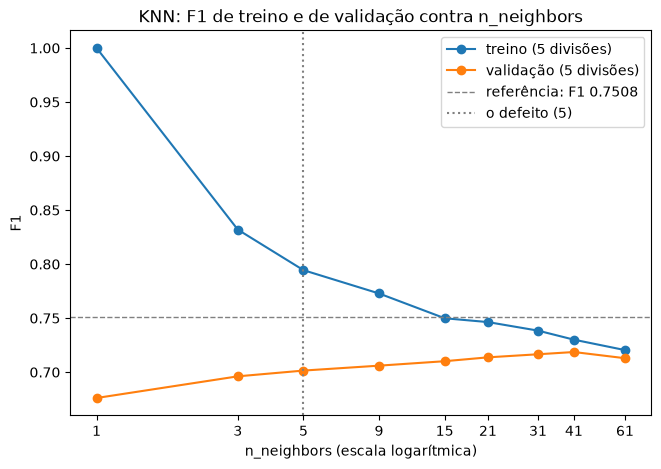

In [23]:
# Passo 22 - o gráfico do Step 28 da W8: F1 de treino e de validação contra n_neighbors. A
# distância entre as duas linhas é o sobreajuste; a tracejado, a referência (regressão logística).
plt.figure(figsize=(7.5, 5))
plt.plot(k_values, [k_runs[f"n_neighbors={value}"]["treino f1"].mean() for value in k_values],
         marker="o", label="treino (5 divisões)")
plt.plot(k_values, [k_runs[f"n_neighbors={value}"]["f1"].mean() for value in k_values],
         marker="o", label="validação (5 divisões)")
plt.axhline(reference["f1"].mean(), color="grey", linestyle="--", linewidth=1,
            label=f"referência: F1 {reference['f1'].mean():.4f}")
plt.axvline(5, color="grey", linestyle=":", linewidth=1.5, label="o defeito (5)")
plt.xscale("log")
plt.xticks(k_values, k_values)
plt.minorticks_off()
plt.xlabel("n_neighbors (escala logarítmica)")
plt.ylabel("F1")
plt.title("KNN: F1 de treino e de validação contra n_neighbors")
plt.legend()
plt.show()

In [24]:
# Passo 23 - weights (W8, Step 29): "uniform" (o defeito) dá um voto igual a cada vizinho;
# "distance" pesa cada um por 1 / distância. Com "distance", cada compra de treino está a
# distância 0 de si própria e fica com o voto todo: o F1 de treino é 1 por construção, e não
# quer dizer sobreajuste a mais do que o resto do modelo.
weight_values = ["uniform", "distance"]
weights_table, weights_runs = sweep({f"weights={value}": KNeighborsClassifier(weights=value)
                                     for value in weight_values})
weights_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
weights=uniform,0.7015,-0.0494,0.0210,0 de 5,pior,0.7944,0.0929,0.6644,56.5863
weights=distance,0.7031,-0.0478,0.0194,0 de 5,pior,1.0000,0.2969,0.6664,56.4935


In [25]:
# Passo 24 - p, a distância (W8, Step 30, célula 110): p=1 soma as diferenças em valor absoluto
# (Manhattan), p=2 é a distância em linha reta (Euclidiana, o defeito), e um p maior deixa a
# maior diferença decidir mais. O `algorithm` (W8, células 116 a 120) só muda o tempo, não os
# vizinhos, por isso não se testa.
p_values = [1, 2, 3]
p_table, p_runs = sweep({f"p={value}": KNeighborsClassifier(p=value) for value in p_values})
p_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
p=1,0.7100,-0.0409,0.0137,0 de 5,pior,0.7955,0.0855,0.6738,56.5306
p=2,0.7015,-0.0494,0.0210,0 de 5,pior,0.7944,0.0929,0.6644,56.5863
p=3,0.6955,-0.0553,0.0219,0 de 5,pior,0.7925,0.0970,0.6579,56.3822


In [26]:
# Passo 25 - a grelha (W8, Step 36, célula 139): n_neighbors x weights x p. A grelha da W8 usa
# os 3 valores de p (54 combinações), mas o p=3 foi o pior no passo 24 e é de longe o mais lento
# (com ele a grelha demora cerca de 6 minutos; sem ele, menos de 1). Fica o p=1 (o melhor) e o
# p=2 (o defeito): 9 x 2 x 2 = 36 combinações.
grid_p = [1, 2]
knn_grid = {f"n_neighbors={k}, weights={w}, p={p}": KNeighborsClassifier(n_neighbors=k, weights=w, p=p)
            for k in k_values for w in weight_values for p in grid_p}
knn_grid_table, knn_grid_runs = sweep(knn_grid)

print(f"{len(knn_grid)} combinações; as 5 melhores pelo F1 médio, e o KNN por defeito:")
knn_default_name = "n_neighbors=5, weights=uniform, p=2"
knn_top = knn_grid_table.sort_values("f1", ascending=False).head(5)
knn_top = pd.concat([knn_top, knn_grid_table.loc[[knn_default_name]]])
knn_top.round(4)

36 combinações; as 5 melhores pelo F1 médio, e o KNN por defeito:


,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
"n_neighbors=41, weights=uniform, p=1",0.7293,-0.0216,0.0096,0 de 5,pior,0.7305,0.0012,0.6967,56.0668
"n_neighbors=41, weights=distance, p=1",0.7284,-0.0225,0.0105,0 de 5,pior,1.0000,0.2716,0.6965,55.8256
"n_neighbors=61, weights=distance, p=1",0.7279,-0.0229,0.0150,0 de 5,pior,1.0000,0.2721,0.6968,55.5659
"n_neighbors=21, weights=uniform, p=1",0.7269,-0.0239,0.0141,0 de 5,pior,0.7448,0.0179,0.6952,55.8813
"n_neighbors=15, weights=distance, p=1",0.7252,-0.0256,0.0128,0 de 5,pior,1.0000,0.2748,0.6928,56.1596
"n_neighbors=5, weights=uniform, p=2",0.7015,-0.0494,0.0210,0 de 5,pior,0.7944,0.0929,0.6644,56.5863


In [27]:
# ===== [4.4] KNN - fim =====
# Passo 26 - o melhor KNN. O que os passos 21 a 25 mostraram (contra a referência, F1 0.7508):
#   - n_neighbors: k=1 decora o treino (F1 de treino 1, validação 0.6761); com mais vizinhos o
#     F1 de treino desce e o de validação sobe até k=41 (0.7186), e volta a descer com k=61.
#     É a mesma forma da W8
#   - weights: "distance" e "uniform" ficam perto (0.7031 contra 0.7015); o F1 de treino 1 de
#     "distance" é por construção (passo 23)
#   - p: a distância de Manhattan (p=1) é a melhor (0.7100), contra 0.7015 da Euclidiana e 0.6955 com p=3,
#     como na W8
#   - a grelha escolhe n_neighbors=41, weights=uniform, p=1: F1 0.7293, -0.0216 contra a referência
#     (2 x SEM = 0.0096, melhor em 0 de 5), accuracy 0.6967; o F1 de treino (0.7305)
#     fica ao nível do de validação, por isso não há sobreajuste, e prevê 1 em 56.1% das
#     compras, perto da taxa real (56%)
#   - nenhum KNN chega à regressão logística: todas as combinações são piores nas 5 divisões.
#     Uma explicação provável: o KNN dá o mesmo peso a todas as colunas, e as colunas one-hot
#     (0 ou 1) e as que quase não se ligam ao alvo pesam tanto na distância como as que
#     importam; a regressão logística aprende um peso para cada coluna
#   - escolhido entre 36 combinações nas mesmas divisões que o medem: o número é otimista
#     (W8, "Nested cross-validation"; a validação aninhada fica para o projeto)
# Entra na tabela do 4.7 como um algoritmo diferente, não como candidato a modelo final.
knn_chosen_name = knn_grid_table["f1"].idxmax()
BEST_KNN = clone(knn_grid[knn_chosen_name])   # para o 4.6 e o 4.7
knn_runs = knn_grid_runs[knn_chosen_name]
print(f"melhor KNN: {knn_chosen_name}")
print(knn_grid_table.loc[[knn_chosen_name]].round(4).to_string())

melhor KNN: n_neighbors=41, weights=uniform, p=1
                                          f1  vs base  2 x SEM melhor em veredicto  F1 treino  treino - validação  accuracy   % de 1
n_neighbors=41, weights=uniform, p=1  0.7293  -0.0216   0.0096    0 de 5      pior     0.7305              0.0012    0.6967  56.0668


In [28]:
# ===== [4.5] ÁRVORE DE DECISÃO - início =====
# Passo 27 - max_depth, uma definição de cada vez (W9, Step 23, célula 71). A árvore faz
# perguntas às colunas ("spend_90d <= x?") e responde com a classe mais frequente da folha
# onde a compra cai. max_depth limita quantas perguntas um caminho pode fazer; o defeito, None,
# deixa crescer até separar quase todas as compras de treino (F1 de treino perto de 1:
# decora o treino). Todas as árvores levam random_state, como na W9.
# A árvore não precisa de escala nem de log1p (W9, célula 22): uma transformação que mantém a
# ordem não muda as perguntas. Usa-se o mesmo prepare_selected para medir na mesma régua.
from sklearn.tree import DecisionTreeClassifier


def tree_size(model):
    """Profundidade e folhas da árvore ajustada em todas as linhas de treino (como a W9).

    O fit_predict ajusta o modelo que recebe, por isso, depois dele, a cópia está ajustada.
    """
    fitted = clone(model)
    fit_predict(prepare_selected, frame, frame, SCALER_FINAL, ENCODER_FINAL, fitted)
    return fitted.get_depth(), fitted.get_n_leaves()


def tree_sweep(setting, values):
    """Uma definição da árvore de cada vez, com as outras no defeito (W9, "The settings")."""
    models = {f"{setting}={value}": DecisionTreeClassifier(random_state=RANDOM_STATE,
                                                            **{setting: value})
              for value in values}
    table, runs = sweep(models)
    table["profundidade"], table["folhas"] = zip(*[tree_size(m) for m in models.values()])
    return table, runs


max_depth_values = [2, 3, 5, 10, None]
depth_table, depth_runs = tree_sweep("max_depth", max_depth_values)
depth_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1,profundidade,folhas
max_depth=2,0.7275,-0.0233,0.0098,0 de 5,pior,0.7025,-0.0251,0.6870,59.0724,2,4
max_depth=3,0.7177,-0.0331,0.0135,0 de 5,pior,0.6946,-0.0232,0.6937,52.8757,3,8
max_depth=5,0.7173,-0.0335,0.0210,0 de 5,pior,0.7387,0.0214,0.6842,55.6401,5,31
max_depth=10,0.6539,-0.0969,0.0295,0 de 5,pior,0.8546,0.2007,0.6258,51.7996,10,329
max_depth=None,0.6255,-0.1254,0.0244,0 de 5,pior,1.0000,0.3745,0.5839,54.9165,48,1247


In [29]:
# Passo 28 - min_samples_leaf (W9, Step 24): cada folha tem de ficar com pelo menos este número
# de compras de treino, por isso cada resposta assenta em mais compras e a árvore não pode
# isolar compras sozinhas. O defeito é 1.
leaf_values = [1, 5, 20, 50]
leaf_table, leaf_runs = tree_sweep("min_samples_leaf", leaf_values)
leaf_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1,profundidade,folhas
min_samples_leaf=1,0.6255,-0.1254,0.0244,0 de 5,pior,1.0000,0.3745,0.5839,54.9165,48,1247
min_samples_leaf=5,0.6663,-0.0846,0.0079,0 de 5,pior,0.8789,0.2126,0.6228,56.8460,33,700
min_samples_leaf=20,0.7107,-0.0401,0.0112,0 de 5,pior,0.7826,0.0719,0.6688,58.1818,20,230
min_samples_leaf=50,0.7299,-0.0210,0.0193,0 de 5,pior,0.7360,0.0061,0.6924,57.6809,11,94


In [30]:
# Passo 29 - min_samples_split (W9, Step 25, célula 88): um nó com menos compras do que isto não
# volta a perguntar. Limita o pai, onde o min_samples_leaf limita os filhos: com o defeito de
# min_samples_leaf=1, um nó de 50 compras ainda se pode dividir em 1 e 49.
split_values = [2, 10, 50]
split_table, split_runs = tree_sweep("min_samples_split", split_values)
split_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1,profundidade,folhas
min_samples_split=2,0.6255,-0.1254,0.0244,0 de 5,pior,1.0000,0.3745,0.5839,54.9165,48,1247
min_samples_split=10,0.6129,-0.1379,0.0290,0 de 5,pior,0.9278,0.3148,0.5794,52.4304,44,848
min_samples_split=50,0.6783,-0.0725,0.0129,0 de 5,pior,0.8132,0.1349,0.6404,55.4917,36,304


In [31]:
# Passo 30 - ccp_alpha, a poda depois de crescer (W9, Step 30, célula 116): a árvore cresce
# toda e depois perde cada ramo que não poupa pelo menos ccp_alpha de impureza por cada folha
# que acrescenta. O defeito, 0.0, não poda nada.
alpha_values = [0.0, 0.0001, 0.001, 0.01]
alpha_table, alpha_runs = tree_sweep("ccp_alpha", alpha_values)
alpha_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1,profundidade,folhas
ccp_alpha=0.0,0.6255,-0.1254,0.0244,0 de 5,pior,1.0000,0.3745,0.5839,54.9165,48,1247
ccp_alpha=0.0001,0.6255,-0.1254,0.0244,0 de 5,pior,1.0000,0.3745,0.5839,54.9165,48,1247
ccp_alpha=0.001,0.6942,-0.0566,0.0578,0 de 5,empata,0.8236,0.1294,0.6638,53.7106,5,19
ccp_alpha=0.01,0.7275,-0.0233,0.0098,0 de 5,pior,0.7025,-0.0251,0.6870,59.0724,2,4


In [32]:
# Passo 31 - as outras quatro definições, cada uma sozinha (W9, Steps 26, 28, 29 e 31):
#   - splitter (célula 95): "best" testa todos os limiares; "random" sorteia um por coluna
#   - criterion (célula 104): a impureza que cada pergunta tem de baixar; "entropy" e "log_loss"
#     são a mesma medida com dois nomes, por isso dão a mesma árvore
#   - max_features (célula 110): quantas colunas cada pergunta pode considerar
#   - class_weight (célula 123): "balanced" dá mais peso à classe menos frequente, aqui a 0
other_settings = {"splitter": ["best", "random"],
                  "criterion": ["gini", "entropy", "log_loss"],
                  "max_features": [None, "sqrt", "log2"],
                  "class_weight": [None, "balanced"]}
other_tables = {}
for setting, values in other_settings.items():
    other_tables[setting], _ = tree_sweep(setting, values)
    print(other_tables[setting][["f1", "vs base", "F1 treino", "accuracy", "% de 1",
                                 "profundidade", "folhas"]].round(4).to_string(), "\n")

                     f1  vs base  F1 treino  accuracy   % de 1  profundidade  folhas
splitter=best    0.6255  -0.1254        1.0    0.5839  54.9165            48    1247
splitter=random  0.6561  -0.0947        1.0    0.6186  54.8609            34    2033 



                        f1  vs base  F1 treino  accuracy   % de 1  profundidade  folhas
criterion=gini      0.6255  -0.1254        1.0    0.5839  54.9165            48    1247
criterion=entropy   0.6496  -0.1012        1.0    0.6056  56.1967            51    1200
criterion=log_loss  0.6496  -0.1012        1.0    0.6056  56.1967            51    1200 



                       f1  vs base  F1 treino  accuracy   % de 1  profundidade  folhas
max_features=None  0.6255  -0.1254        1.0    0.5839  54.9165            48    1247
max_features=sqrt  0.6630  -0.0878        1.0    0.6245  55.4174            40    1882
max_features=log2  0.6634  -0.0875        1.0    0.6243  55.6586            40    2019 



                           f1  vs base  F1 treino  accuracy   % de 1  profundidade  folhas
class_weight=None      0.6255  -0.1254        1.0    0.5839  54.9165            48    1247
class_weight=balanced  0.6361  -0.1148        1.0    0.5926  55.7143            48    1418 



In [33]:
# Passo 32 - duas formas de podar (W9, "Two ways to prune", Step 34, célula 135): o melhor valor
# de cada definição que poda antes de crescer (max_depth, min_samples_leaf, min_samples_split)
# e da que poda depois (ccp_alpha), ao lado da árvore por defeito.
pruning_rows = []
for kind, table in [("nenhuma (defeito)", depth_table.loc[["max_depth=None"]]),
                    ("antes de crescer", depth_table), ("antes de crescer", leaf_table),
                    ("antes de crescer", split_table), ("depois de crescer", alpha_table)]:
    best = table["f1"].idxmax()
    pruning_rows.append({"poda": kind, "árvore": best,
                         **table.loc[best, ["profundidade", "folhas", "f1", "F1 treino",
                                            "accuracy", "vs base", "veredicto"]].to_dict()})
pruning_table = pd.DataFrame(pruning_rows).set_index("árvore")
pruning_table.round(4)

,poda,profundidade,folhas,f1,F1 treino,accuracy,vs base,veredicto
árvore,,,,,,,,
max_depth=None,nenhuma (defeito),48,1247,0.6255,1.0000,0.5839,-0.1254,pior
max_depth=2,antes de crescer,2,4,0.7275,0.7025,0.6870,-0.0233,pior
min_samples_leaf=50,antes de crescer,11,94,0.7299,0.7360,0.6924,-0.0210,pior
min_samples_split=50,antes de crescer,36,304,0.6783,0.8132,0.6404,-0.0725,pior
ccp_alpha=0.01,depois de crescer,2,4,0.7275,0.7025,0.6870,-0.0233,pior


In [34]:
# Passo 33 - a grelha (W9, Step 38): só com os 3 parâmetros que mais mexeram no F1 (passos 27 a
# 31): max_depth, min_samples_leaf e ccp_alpha. A grelha da W9 junta as 8 definições (256
# combinações); aqui ficaria demasiado lenta. O ccp_alpha=0.0001 sai: não poda nada e dá a
# mesma árvore que 0.0 (passo 30, como na W9). 5 x 4 x 3 = 60 combinações.
tree_grid = {f"max_depth={d}, min_samples_leaf={leaf}, ccp_alpha={alpha}":
             DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, ccp_alpha=alpha,
                                    random_state=RANDOM_STATE)
             for d in max_depth_values for leaf in leaf_values for alpha in [0.0, 0.001, 0.01]}
tree_grid_table, tree_grid_runs = sweep(tree_grid)

print(f"{len(tree_grid)} combinações; as 5 melhores pelo F1 médio, e a árvore por defeito:")
tree_default_name = "max_depth=None, min_samples_leaf=1, ccp_alpha=0.0"
tree_top = tree_grid_table.sort_values("f1", ascending=False).head(5)
tree_top = pd.concat([tree_top, tree_grid_table.loc[[tree_default_name]]])
tree_top.round(4)

60 combinações; as 5 melhores pelo F1 médio, e a árvore por defeito:


,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
"max_depth=5, min_samples_leaf=50, ccp_alpha=0.001",0.7303,-0.0206,0.0168,1 de 5,pior,0.7151,-0.0152,0.7058,53.1911
"max_depth=10, min_samples_leaf=50, ccp_alpha=0.0",0.7299,-0.0210,0.0193,0 de 5,pior,0.7360,0.0061,0.6924,57.6809
"max_depth=None, min_samples_leaf=50, ccp_alpha=0.0",0.7299,-0.0210,0.0193,0 de 5,pior,0.7360,0.0061,0.6924,57.6809
"max_depth=5, min_samples_leaf=50, ccp_alpha=0.0",0.7298,-0.0210,0.0190,1 de 5,pior,0.7222,-0.0076,0.6950,56.7532
"max_depth=None, min_samples_leaf=50, ccp_alpha=0.001",0.7289,-0.0220,0.0177,1 de 5,pior,0.7196,-0.0093,0.7050,52.9685
"max_depth=None, min_samples_leaf=1, ccp_alpha=0.0",0.6255,-0.1254,0.0244,0 de 5,pior,1.0000,0.3745,0.5839,54.9165


In [35]:
# ===== [4.5] ÁRVORE DE DECISÃO - fim =====
# Passo 34 - a melhor árvore. O que os passos 27 a 33 mostraram (contra a referência, F1 0.7508):
#   - por defeito, a árvore decora o treino: F1 de treino 1 e de validação perto de 0.63, com
#     profundidade 48 e 1247 folhas (sobreajuste, como na W9)
#   - limitar o crescimento é o que mais ajuda: min_samples_leaf=50 dá 0.7299 (94 folhas),
#     max_depth=2 dá 0.7275 com só 4 folhas; aí o F1 de treino (0.7025) e o de validação ficam
#     baixos e próximos, o sinal de subajuste da W5 ("Model Selection Workflow", ponto 2)
#   - podar depois (ccp_alpha=0.01) chega ao mesmo que max_depth=2: as duas dão a mesma árvore
#     de 4 folhas (passo 32). O ccp_alpha=0.001 varia muito entre divisões (2 x SEM = 0.058)
#   - splitter, criterion, max_features e class_weight mudam a árvore sem limites em alguns
#     centésimos, mas nenhum se aproxima do que limitar o crescimento consegue (passo 31);
#     "entropy" e "log_loss" dão a mesma árvore
#   - as árvores grandes (passos 27 a 31) dão F1 ligeiramente diferentes de computador para
#     computador: com dezenas de níveis, pequenos arredondamentos mudam as divisões mais
#     fundas. As árvores pequenas do topo da grelha, a escolhida e a submissão não mudam
#   - a grelha escolhe max_depth=5, min_samples_leaf=50, ccp_alpha=0.001: F1 0.7303, -0.0206
#     contra a referência (2 x SEM = 0.0168, melhor em 1 de 5), accuracy 0.7058, prevê 1 em 53%
#     das compras, com 14 folhas; o F1 de treino (0.7151) fica ao nível do de validação, sem
#     sobreajuste. As 5 melhores da grelha ficam todas entre 0.729 e 0.730: há uma zona boa,
#     não um vencedor
#   - nenhuma árvore chega à regressão logística: quase todas as 60 combinações são piores, e
#     as poucas que "empatam" só empatam porque variam muito entre divisões
#   - escolhida entre 60 combinações nas mesmas divisões que a medem: o número é otimista
#     (W9, "Nested cross-validation"; a validação aninhada fica para o projeto)
# Entra na tabela do 4.7 como um algoritmo diferente, não como candidato a modelo final.
tree_chosen_name = tree_grid_table["f1"].idxmax()
BEST_TREE = clone(tree_grid[tree_chosen_name])   # para o 4.6 e o 4.7
tree_runs = tree_grid_runs[tree_chosen_name]
print(f"melhor árvore: {tree_chosen_name}, com {tree_size(BEST_TREE)[1]} folhas no treino inteiro")
print(tree_grid_table.loc[[tree_chosen_name]].round(4).to_string())

melhor árvore: max_depth=5, min_samples_leaf=50, ccp_alpha=0.001, com 14 folhas no treino inteiro
                                                       f1  vs base  2 x SEM melhor em veredicto  F1 treino  treino - validação  accuracy   % de 1
max_depth=5, min_samples_leaf=50, ccp_alpha=0.001  0.7303  -0.0206   0.0168    1 de 5      pior     0.7151             -0.0152    0.7058  53.1911


In [36]:
# ===== [4.6] LIMIAR DE DECISÃO - início =====
# Passo 35 - as probabilidades. A regressão logística, o Naive Bayes, o KNN e a árvore dão uma
# probabilidade da classe 1, e o predict diz 1 quando ela chega a 0.5 (W5, secção 2.7). Para
# escolher outro limiar é preciso essa probabilidade, como o y_pred_proba_val da W5 (Step 39):
# em cada divisão, o modelo treina no passado e dá a probabilidade às compras da validação. As
# 5 validações juntam-se numa só, e cada modelo recebe um limiar (o que se aplica ao test.csv).
# Os 4 modelos, porque a tabela final do 4.7 pede cada um com e sem limiar.
# Os imports ficam aqui para não mexer na célula de imports.
from sklearn.metrics import precision_recall_curve, roc_curve

best_models = {"regressão logística": BEST_LOGISTIC, "Naive Bayes": BEST_NAIVE_BAYES,
               "KNN": BEST_KNN, "árvore de decisão": BEST_TREE}


def pooled_probabilities(model):
    """As probabilidades da classe 1 nas 5 validações, juntas, e o alvo verdadeiro."""
    probabilities, truth = [], []
    for train_idx, val_idx in splits:
        train, valid = frame.iloc[train_idx], frame.iloc[val_idx]
        probabilities.append(fit_predict(prepare_selected, train, valid, SCALER_FINAL,
                                         ENCODER_FINAL, model, proba=True))
        truth.append(valid[TARGET].to_numpy())
    return np.concatenate(probabilities), np.concatenate(truth)


pooled = {name: pooled_probabilities(model) for name, model in best_models.items()}
for name, (probability, truth) in pooled.items():
    print(f"{name}: {len(probability):,} probabilidades, {len(np.unique(probability)):,} valores"
          f" diferentes, de {probability.min():.4f} a {probability.max():.4f}")

regressão logística: 5,390 probabilidades, 5,390 valores diferentes, de 0.0014 a 0.9984
Naive Bayes: 5,390 probabilidades, 5,390 valores diferentes, de 0.2688 a 0.9912
KNN: 5,390 probabilidades, 41 valores diferentes, de 0.0244 a 1.0000
árvore de decisão: 5,390 probabilidades, 72 valores diferentes, de 0.1094 a 0.9897


In [37]:
# Passo 36 - o limiar de cada modelo, pelos dois métodos da W5: o maior F1 na curva
# precision-recall (Step 40), que é o que decide porque o F1 é a nossa métrica e a do Kaggle, e
# o índice de Youden na curva ROC (Step 37), ao lado. A tabela é a do Step 42: as métricas nas
# validações juntas com o limiar de cada método.
def metrics_at(probability, truth, threshold):
    """As métricas dos rótulos que o limiar dá (W5, Step 33), mais a % de previsões 1."""
    labels = (probability >= threshold).astype(int)
    return {"limiar": threshold, "accuracy": accuracy_score(truth, labels),
            "precision": precision_score(truth, labels, zero_division=0),
            "recall": recall_score(truth, labels), "F1": f1_score(truth, labels, zero_division=0),
            "% de 1": 100 * labels.mean()}


chosen_thresholds, method_rows = {}, []
for name, (probability, truth) in pooled.items():
    # W5, Step 40: o F1 de cada limiar da curva precision-recall, e o maior
    precision, recall, thresholds_pr = precision_recall_curve(truth, probability)
    f1_scores = np.where((precision + recall) == 0, 0,
                         2 * (precision * recall) / (precision + recall))
    optimal_threshold_pr = thresholds_pr[np.argmax(f1_scores)]
    # W5, Step 37: o índice de Youden (TPR - FPR) na curva ROC
    fpr, tpr, thresholds = roc_curve(truth, probability)
    optimal_threshold_roc = thresholds[np.argmax(tpr - fpr)]
    chosen_thresholds[name] = float(optimal_threshold_pr)
    for method, threshold in [("por defeito", 0.5), ("ROC (Youden)", optimal_threshold_roc),
                              ("PR (maior F1)", optimal_threshold_pr)]:
        method_rows.append({"modelo": name, "método": method,
                            **metrics_at(probability, truth, threshold)})
pd.DataFrame(method_rows).set_index(["modelo", "método"]).round(4)

limiar  accuracy  precision  recall  \
modelo              método                                               
regressão logística por defeito    0.5000    0.7219     0.7500  0.7601   
                    ROC (Youden)   0.5589    0.7208     0.7803  0.7025   
                    PR (maior F1)  0.4398    0.7104     0.7155  0.8075   
Naive Bayes         por defeito    0.5000    0.6212     0.6039  0.9533   
                    ROC (Youden)   0.8175    0.6733     0.7667  0.6045   
                    PR (maior F1)  0.5651    0.6481     0.6284  0.9197   
KNN                 por defeito    0.5000    0.6967     0.7323  0.7282   
                    ROC (Youden)   0.6341    0.6833     0.8124  0.5699   
                    PR (maior F1)  0.3659    0.6540     0.6379  0.8937   
árvore de decisão   por defeito    0.5000    0.7035     0.7423  0.7262   
                    ROC (Youden)   0.6073    0.7028     0.7808  0.6575   
                    PR (maior F1)  0.3797    0.6711     0.6651  0.8391   

                                       F1   % de 1  
modelo              método                          
regressão logística por defeito    0.7550  57.1429  
                    ROC (Youden)   0.7394  50.7607  
                    PR (maior F1)  0.7587  63.6364  
Naive Bayes         por defeito    0.7394  88.9981  
                    ROC (Youden)   0.6760  44.4527  
                    PR (maior F1)  0.7466  82.5232  
KNN                 por defeito    0.7302  56.0668  
                    ROC (Youden)   0.6699  39.5547  
                    PR (maior F1)  0.7444  78.9981  
árvore de decisão   por defeito    0.7342  55.1577  
                    ROC (Youden)   0.7138  47.4768  
                    PR (maior F1)  0.7420  71.1317

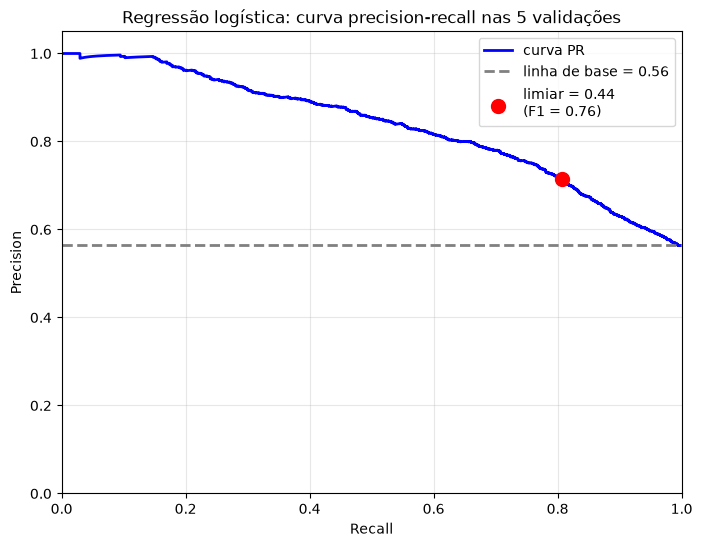

In [38]:
# Passo 37 - o gráfico do Step 41 da W5, só para a regressão logística (o melhor modelo do 4.2 ao
# 4.5): a curva precision-recall nas validações juntas, a linha de base (a parte de compras com
# recompra) e o ponto do maior F1.
probability, truth = pooled["regressão logística"]
precision, recall, thresholds_pr = precision_recall_curve(truth, probability)
f1_scores = np.where((precision + recall) == 0, 0, 2 * (precision * recall) / (precision + recall))
optimal_idx_pr = np.argmax(f1_scores)
baseline = truth.sum() / len(truth)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color="blue", lw=2, label="curva PR")
plt.axhline(y=baseline, color="gray", linestyle="--", lw=2, label=f"linha de base = {baseline:.2f}")
plt.scatter(recall[optimal_idx_pr], precision[optimal_idx_pr], color="red", s=100, zorder=5,
            label=f"limiar = {thresholds_pr[optimal_idx_pr]:.2f}\n(F1 = {f1_scores[optimal_idx_pr]:.2f})")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Regressão logística: curva precision-recall nas 5 validações")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.show()

In [39]:
# Passo 38 - "0.5 contra o limiar escolhido", divisão a divisão: cada modelo com o seu limiar da
# curva PR contra o mesmo modelo com 0.5, nas mesmas 5 divisões, com a regra dos 2 x SEM. A
# accuracy e a % de 1 ficam ao lado: baixar o limiar faz o modelo dizer 1 mais vezes, e isso
# sobe o F1 quase sempre (tarefa 3; W5, key takeaway 3).
# os resultados com 0.5 já existem (passos 14, 20, 26 e 34): não se treina outra vez
model_runs = {"regressão logística": logistic_runs, "Naive Bayes": naive_bayes_runs,
              "KNN": knn_runs, "árvore de decisão": tree_runs}
threshold_rows = []
threshold_runs = {}
for name, model in best_models.items():
    at_05 = model_runs[name]
    at_chosen = run_model(model, chosen_thresholds[name])
    threshold_runs[name] = at_chosen
    for metric in ["f1", "accuracy"]:
        diff = compare({name: at_chosen}, at_05, metric=metric).astype({"vs base": float,
                                                                         "SEM": float})
        diff["veredicto"] = verdict(diff)
        threshold_rows.append({"modelo": name, "métrica": metric,
                               "0.5": at_05[metric].mean(),
                               "limiar": chosen_thresholds[name],
                               "com o limiar": at_chosen[metric].mean(),
                               "diferença": diff["vs base"].iloc[0],
                               "2 x SEM": 2 * diff["SEM"].iloc[0],
                               "melhor em": diff["melhor em"].iloc[0],
                               "veredicto": diff["veredicto"].iloc[0],
                               "% de 1 (0.5)": at_05["% de 1"].mean(),
                               "% de 1 (limiar)": at_chosen["% de 1"].mean()})
pd.DataFrame(threshold_rows).set_index(["modelo", "métrica"]).round(4)

0.5  limiar  com o limiar  diferença  \
modelo              métrica                                             
regressão logística f1        0.7540  0.4398        0.7579     0.0039   
                    accuracy  0.7219  0.4398        0.7104    -0.0115   
Naive Bayes         f1        0.7390  0.5651        0.7461     0.0071   
                    accuracy  0.6212  0.5651        0.6481     0.0269   
KNN                 f1        0.7293  0.3659        0.7435     0.0143   
                    accuracy  0.6967  0.3659        0.6540    -0.0427   
árvore de decisão   f1        0.7303  0.3797        0.7413     0.0111   
                    accuracy  0.7058  0.3797        0.6711    -0.0347   

                              2 x SEM melhor em veredicto  % de 1 (0.5)  \
modelo              métrica                                               
regressão logística f1         0.0064    4 de 5    empata       57.1429   
                    accuracy   0.0084    0 de 5      pior       57.1429   
Naive Bayes         f1         0.0085    4 de 5    empata       88.9981   
                    accuracy   0.0155    5 de 5    melhor       88.9981   
KNN                 f1         0.0156    4 de 5    empata       56.0668   
                    accuracy   0.0217    0 de 5      pior       56.0668   
árvore de decisão   f1         0.0114    4 de 5    empata       53.1911   
                    accuracy   0.0211    0 de 5      pior       53.1911   

                              % de 1 (limiar)  
modelo              métrica                    
regressão logística f1                63.6364  
                    accuracy          63.6364  
Naive Bayes         f1                82.5232  
                    accuracy          82.5232  
KNN                 f1                78.9981  
                    accuracy          78.9981  
árvore de decisão   f1                71.1317  
                    accuracy          71.1317

In [40]:
# ===== [4.6] LIMIAR DE DECISÃO - fim =====
# Passo 39 - o limiar de cada modelo. O que os passos 35 a 38 mostraram:
#   - pela curva PR (maior F1), a regressão logística fica com 0.44, o KNN com 0.37 e a árvore com
#     0.38: os três baixam o limiar e passam a prever mais 1s (64%, 79% e 71%, contra 53 a 57%
#     com 0.5). O Naive Bayes é o único que o sobe (0.57), porque com 0.5 já previa 1 em 89%
#   - o índice de Youden (ROC) sobe o limiar nos 4 e baixa o F1: maximiza TPR - FPR, que conta
#     os dois erros por igual, e não o F1 (W5, Step 42: cada método escolhe outro limiar)
#   - divisão a divisão (passo 38), nenhum limiar passa os 2 x SEM no F1: todos empatam com 0.5
#     (regressão logística +0.0039 com 2 x SEM 0.0064). Na accuracy, a regressão logística, o
#     KNN e a árvore pioram; só o Naive Bayes melhora, porque deixa de prever quase sempre 1
#   - o F1 das validações juntas (passo 36, 0.7550 com 0.5) não é a média das 5 divisões (0.7540,
#     passo 38): a média por divisão é a que se compara, como em todo o notebook
#   - o limiar foi escolhido nas mesmas validações onde é medido, por isso até estes ganhos
#     pequenos são otimistas (W5, key takeaway 5)
# Decisão: com a regra dos 2 x SEM, nenhum limiar é uma melhoria provada; fica o 0.5 (o predict
# de cada modelo, threshold=None) nos 4. O 4.7 mostra cada modelo com e sem limiar, como pede o
# plano. Também por isto a Version05 (limiar 0.45) não é uma melhoria provada.
THRESHOLDS = {}
for row in threshold_rows:
    if row["métrica"] == "f1":
        THRESHOLDS[row["modelo"]] = row["limiar"] if row["veredicto"] == "melhor" else None
print("limiar de cada modelo para o 4.7 (None = 0.5):", THRESHOLDS)
print("limiares da curva PR, para a tabela do 4.7:", {name: round(value, 4)
                                                    for name, value in chosen_thresholds.items()})

limiar de cada modelo para o 4.7 (None = 0.5): {'regressão logística': None, 'Naive Bayes': None, 'KNN': None, 'árvore de decisão': None}
limiares da curva PR, para a tabela do 4.7: {'regressão logística': 0.4398, 'Naive Bayes': 0.5651, 'KNN': 0.3659, 'árvore de decisão': 0.3797}


In [41]:
# ===== [4.7] MODELO FINAL - início =====
# Passo 40 - a tabela final: o melhor de cada algoritmo (4.2 a 4.5), com o limiar 0.5 e com o
# limiar da curva PR (4.6), contra a referência, nas mesmas 5 divisões. É o "number we stand
# behind" de cada aula, lado a lado. Não se treina nada de novo: os resultados por divisão vêm
# dos passos 14, 20, 26, 34 (limiar 0.5) e 38 (limiar da curva PR).
final_runs = {"referência (regressão logística por defeito)": reference}
for name, runs in model_runs.items():
    final_runs[f"{name}, limiar 0.5"] = runs
    final_runs[f"{name}, limiar {chosen_thresholds[name]:.2f}"] = threshold_runs[name]

# as mesmas colunas do sweep (passo 3)
final_table = compare(final_runs, reference, metric="f1").astype(
    {"f1": float, "accuracy": float, "vs base": float, "SEM": float})
final_table["2 x SEM"] = 2 * final_table["SEM"]
final_table["veredicto"] = verdict(final_table)
final_table["F1 treino"] = [final_runs[name]["treino f1"].mean() for name in final_table.index]
final_table["treino - validação"] = final_table["F1 treino"] - final_table["f1"]
final_table["% de 1"] = [final_runs[name]["% de 1"].mean() for name in final_table.index]
final_table = final_table[["f1", "vs base", "2 x SEM", "melhor em", "veredicto", "F1 treino",
                           "treino - validação", "accuracy", "% de 1"]]
final_table.round(4)

,f1,vs base,2 x SEM,melhor em,veredicto,F1 treino,treino - validação,accuracy,% de 1
referência (regressão logística por defeito),0.7508,0.0000,0.0000,0 de 5,empata,0.7316,-0.0192,0.7163,57.8850
"regressão logística, limiar 0.5",0.7540,0.0031,0.0028,5 de 5,melhor,0.7309,-0.0231,0.7219,57.1429
"regressão logística, limiar 0.44",0.7579,0.0070,0.0051,5 de 5,melhor,0.7437,-0.0142,0.7104,63.6364
"Naive Bayes, limiar 0.5",0.7390,-0.0119,0.0163,1 de 5,empata,0.7175,-0.0215,0.6212,88.9981
"Naive Bayes, limiar 0.57",0.7461,-0.0047,0.0136,1 de 5,empata,0.7130,-0.0332,0.6481,82.5232
"KNN, limiar 0.5",0.7293,-0.0216,0.0096,0 de 5,pior,0.7305,0.0012,0.6967,56.0668
"KNN, limiar 0.37",0.7435,-0.0073,0.0136,1 de 5,empata,0.7500,0.0065,0.6540,78.9981
"árvore de decisão, limiar 0.5",0.7303,-0.0206,0.0168,1 de 5,pior,0.7151,-0.0152,0.7058,53.1911
"árvore de decisão, limiar 0.38",0.7413,-0.0095,0.0107,1 de 5,empata,0.7464,0.0051,0.6711,71.1317


In [42]:
# Passo 41 - a escolha, com a regra do plano e das aulas:
#   1. contam só as linhas "melhor" do que a referência (regra dos 2 x SEM); se nenhuma for,
#      fica a referência
#   2. dessas, a de maior F1 médio
#   3. se outra empatar com ela, divisão a divisão, fica a mais simples: "when a more complicated
#      model only matches a simpler one, the simpler one is the better choice" (W6, fim da aula).
#      Mais simples quer dizer sem limiar (o predict do modelo, uma escolha a menos) e, entre
#      algoritmos, pela ordem regressão logística (o modelo de base da W6), Naive Bayes, KNN,
#      árvore
# Resultado (passo 40): só 2 linhas são melhores do que a referência, as duas da regressão
# logística. A de maior F1 é a do limiar 0.44 (+0.0070), mas empata com a mesma regressão com
# 0.5 (passo 38), e prevê 1 em 64% das compras com accuracy mais baixa. Fica a de 0.5. Os outros
# 3 algoritmos empatam ou perdem com a referência, com ou sem limiar. Todos foram escolhidos nas
# mesmas divisões que os medem, por isso os números são otimistas; a validação aninhada (W5 a
# W9) fica para o projeto.
better = final_table[final_table["veredicto"] == "melhor"]
if better.empty:
    final_name = "referência"
else:
    top_name = better["f1"].idxmax()
    ties = compare({name: final_runs[name] for name in better.index}, final_runs[top_name])
    ties = ties.astype({"f1": float, "vs base": float, "SEM": float})
    ties["2 x SEM"] = 2 * ties["SEM"]
    ties["veredicto"] = verdict(ties)
    print(f"{len(better)} linhas melhores do que a referência; a de maior F1: {top_name}")
    print(ties[["f1", "vs base", "2 x SEM", "melhor em", "veredicto"]].round(4).to_string())
    simplest_first = ([f"{name}, limiar 0.5" for name in model_runs]
                      + [f"{name}, limiar {chosen_thresholds[name]:.2f}" for name in model_runs])
    final_name = next(name for name in simplest_first
                      if name in ties.index and ties.loc[name, "veredicto"] != "pior")
print(f"\nmodelo final: {final_name}")

2 linhas melhores do que a referência; a de maior F1: regressão logística, limiar 0.44
                                      f1  vs base  2 x SEM melhor em veredicto
regressão logística, limiar 0.5   0.7540  -0.0039   0.0064    1 de 5    empata
regressão logística, limiar 0.44  0.7579   0.0000   0.0000    0 de 5    empata

modelo final: regressão logística, limiar 0.5


In [43]:
# ===== [4.7] MODELO FINAL - fim =====
# Passo 42 - o modelo final, com os parâmetros escritos à mão (o enunciado do projeto pede-o para
# os modelos escolhidos por grelha). É a regressão logística do passo 14:
#   - solver="saga", l1_ratio=1.0: a penalização L1 (W6), que pode pôr pesos a zero
#   - C=100: penalização fraca; com C de 1 para cima as três formas ficam perto (passo 9)
#   - fit_intercept=False: as colunas one-hot de cada variável somam 1 em cada linha, por isso
#     os seus pesos já fazem o papel da constante; com e sem ela empata (passo 12)
#   - max_iter=5000 e random_state, como na W6
#   - limiar 0.44, o da curva precision-recall do passo 36 (0.4398, arredondado à mão). É uma
#     exceção à regra "empate -> o mais simples" do passo 41, pelos motivos seguintes:
#       1. a métrica do Kaggle é o F1, e o método da W5 para escolher o limiar que maximiza o
#          F1 é o maior F1 na curva precision-recall (Steps 40 a 42)
#       2. nas validações, 0.44 dá mais F1 do que 0.5 (+0.0035; o 0.4398 exato dá +0.0039, passo
#          38), mas dentro do ruído
#          e com menos accuracy: prevê mais 1s
#       3. o Kaggle confirma, sem ter servido para escolher: a Version05 (limiar 0.45, mais 1s)
#          teve 0.79093 e a Version06 (limiar 0.5) 0.78328
#     Cuidado: o limiar foi escolhido nas mesmas validações que o medem, por isso o ganho é
#     otimista (W5, key takeaway 5)
# A verificação avisa se, neste computador, a escolha automática (passos 13 e 41) der outro
# modelo: a grelha desempata por 0.0002, e outro computador pode desempatar ao contrário. O
# modelo final continua a ser este, escrito à mão.
FINAL_MODEL = LogisticRegression(solver="saga", l1_ratio=1.0, C=100, fit_intercept=False,
                                 max_iter=5000, random_state=RANDOM_STATE)
FINAL_THRESHOLD = 0.44   # curva precision-recall do passo 36

if (final_name != "regressão logística, limiar 0.5"
        or FINAL_MODEL.get_params() != BEST_LOGISTIC.get_params()):
    print(f"aviso: neste computador a escolha automática deu '{final_name}'"
          f" ({logistic_chosen_name}); o modelo final continua a ser o escrito à mão")
final_run = run_model(FINAL_MODEL, FINAL_THRESHOLD)
print(f"modelo final: F1 {final_run['f1'].mean():.4f} +- {sem(final_run['f1']):.4f},"
      f" accuracy {final_run['accuracy'].mean():.4f}, prevê 1 em {final_run['% de 1'].mean():.1f}%"
      " das compras")
print(f"contra a referência: F1 {final_run['f1'].mean() - reference['f1'].mean():+.4f},"
      f" accuracy {final_run['accuracy'].mean() - reference['accuracy'].mean():+.4f}")
print(f"contra o mesmo modelo com 0.5: F1 {final_run['f1'].mean() - logistic_runs['f1'].mean():+.4f},"
      f" accuracy {final_run['accuracy'].mean() - logistic_runs['accuracy'].mean():+.4f},"
      f" % de 1 {logistic_runs['% de 1'].mean():.1f} -> {final_run['% de 1'].mean():.1f}")

modelo final: F1 0.7575 +- 0.0083, accuracy 0.7100, prevê 1 em 63.6% das compras
contra a referência: F1 +0.0067, accuracy -0.0063
contra o mesmo modelo com 0.5: F1 +0.0035, accuracy -0.0119, % de 1 57.1 -> 63.6


In [44]:
# ===== [4.8] TABELA DE DECISÕES =====
# Passo 43 - o que a tarefa 4 testou e decidiu, uma linha por pacote, como na tarefa 2 (02, passo
# 37) e na tarefa 3 (02, passo 60). Os números vêm das células anteriores, por isso mudam com elas.
# É a base do PDF da tarefa 5 e da comparação entre modelos candidatos do projeto.
def best(table, name):
    """F1, diferença contra a referência e veredicto de uma linha de uma tabela do sweep."""
    row = table.loc[name]
    return f"F1 {row['f1']:.4f} ({row['vs base']:+.4f}, {row['veredicto']})"


logistic_threshold = next(row for row in threshold_rows
                          if row["modelo"] == "regressão logística" and row["métrica"] == "f1")
nb_row = nb_grid_table.loc[nb_chosen_name]
task4_decisions = pd.DataFrame([
    ("4.0", "régua dos modelos: run_model e sweep",
     f"referência (regressão logística por defeito): F1 {reference['f1'].mean():.4f},"
     f" accuracy {reference['accuracy'].mean():.4f}",
     "todos os modelos são medidos contra ela, nas mesmas 5 divisões"),
    ("4.1", "estratégia de avaliação e métrica",
     "validação cruzada por tempo (TimeSeriesSplit, 5 divisões); prever sempre 1 dá F1 0.721",
     "F1 decide (é a métrica do Kaggle); accuracy, precision e recall ao lado"),
    ("4.2", f"regressão logística: C, L1/L2/elastic net, class_weight, fit_intercept;"
            f" grelha de {len(grid)}",
     f"{logistic_chosen_name}: {best(grid_table, logistic_chosen_name)}",
     "fica: a única melhor do que a referência"),
    ("4.3", f"Naive Bayes: var_smoothing, priors, calibração; grelha de {len(nb_grid)}",
     f"{best(nb_grid_table, nb_chosen_name)}, mas prevê 1 em {nb_row['% de 1']:.0f}% e a"
     f" accuracy cai para {nb_row['accuracy']:.4f}",
     "não fica: ganha F1 só por prever mais 1s"),
    ("4.4", f"KNN: n_neighbors, weights, p; grelha de {len(knn_grid)}",
     f"{knn_chosen_name}: {best(knn_grid_table, knn_chosen_name)}",
     "não fica: todas as combinações abaixo da referência"),
    ("4.5", f"árvore de decisão: profundidade, folhas, poda e outras 4 definições;"
            f" grelha de {len(tree_grid)}",
     f"{tree_chosen_name}: {best(tree_grid_table, tree_chosen_name)}",
     "não fica: sem limites decora o treino; limitada fica abaixo"),
    ("4.6", "limiar: curva precision-recall (maior F1) e índice de Youden, nos 4 modelos",
     f"regressão logística com {logistic_threshold['limiar']:.2f}:"
     f" {logistic_threshold['diferença']:+.4f} contra 0.5 ({logistic_threshold['veredicto']})",
     "nenhum limiar passa os 2 x SEM; no modelo final fica 0.44 (passo 42)"),
    ("4.7", "modelo final: a regra dos 2 x SEM (passo 41) e o limiar da curva PR (passo 42)",
     f"F1 {final_run['f1'].mean():.4f}, accuracy {final_run['accuracy'].mean():.4f}"
     f" (referência: F1 {reference['f1'].mean():.4f})",
     "regressão logística L1, C=100, sem constante, limiar 0.44: Version07"),
], columns=["pacote", "o que se testou", "resultado", "decisão"])
print(task4_decisions.to_string(index=False))

pacote                                                                      o que se testou                                                                              resultado                                                                 decisão
   4.0                                                 régua dos modelos: run_model e sweep               referência (regressão logística por defeito): F1 0.7508, accuracy 0.7163          todos os modelos são medidos contra ela, nas mesmas 5 divisões
   4.1                                                    estratégia de avaliação e métrica validação cruzada por tempo (TimeSeriesSplit, 5 divisões); prever sempre 1 dá F1 0.721 F1 decide (é a métrica do Kaggle); accuracy, precision e recall ao lado
   4.2 regressão logística: C, L1/L2/elastic net, class_weight, fit_intercept; grelha de 24         L1, C=100, class_weight=None, fit_intercept=False: F1 0.7540 (+0.0031, melhor)                                fica: a única melhor do que a referên

In [45]:
# ===== SUBMISSÃO AO KAGGLE - início =====
# Passo 44 - a célula que gera o ficheiro passou do 02 para aqui: o modelo escolhe-se neste
# notebook, e o enunciado do projeto (V. Deployment) pede que a última parte aplique o pipeline
# ao test.csv. Primeiro, a prova de que nada mudou na passagem: sem limiar, a preparação final
# e a regressão logística, ajustadas no treino inteiro, dão exatamente a Version04.
version_04 = pd.read_csv("../submissions/ML_Group_37_Version04.csv", index_col="ID")[TARGET]
same_as_04 = fit_predict(prepare_selected, frame, test_csv, SCALER_FINAL, ENCODER_FINAL)
# até 2 previsões diferentes são arredondamentos de outro computador; mais é outro pipeline
different_04 = int((same_as_04 != version_04.loc[test_csv.index].to_numpy()).sum())
assert different_04 <= 2, f"{different_04} previsões diferentes da Version04"
print(f"sem limiar, o 03 reproduz a Version04: {len(same_as_04) - different_04} de"
      f" {len(same_as_04)} previsões iguais")

sem limiar, o 03 reproduz a Version04: 986 de 986 previsões iguais


In [46]:
# Passo 45 - a submissão. Histórico (score = a parte visível da leaderboard, 70% do teste):
#   Version01  preparação do 2.2, regressão logística                 F1 local 0.734  Kaggle 0.77
#   Version02  as mesmas previsões da Version01                                        Kaggle ?
#   Version03  preparação final do 2.7                                F1 local 0.748  Kaggle ?
#   Version04  + as features da tarefa 3 (sem as 14 colunas)          F1 local 0.751  Kaggle ?
#   Version05  a Version04 com limiar 0.45 (W5, secção 2.7)            F1 local 0.753  Kaggle 0.79093
#   Version06  L1, C=100, sem constante, limiar 0.5                    F1 local 0.754  Kaggle 0.78328
#   Version07  a Version06 com o limiar da curva PR, 0.44 (passo 42)   F1 local 0.758  Kaggle ?
# A Version05 é uma sonda, não uma melhoria provada: localmente o limiar 0.45 empata no F1
# (+0.0026, 2 x SEM = 0.0043) e piora a accuracy (-0.011). Prevê mais 1s (697 contra 649),
# como o sample_submission (741), que teve 0.779 contra os 0.77 da Version01. Se subir, é sinal
# de que a métrica do Kaggle premeia prever mais 1s. Não se escolhe o modelo final por isto.
# A Version07 é o modelo final do passo 42: o modelo da Version06 com o limiar que maximiza o F1
# na curva precision-recall. É a que fica escolhida em "My Submissions": a escolha vem das
# validações e do método da W5, não da leaderboard pública, que só usa 70% do teste.
# VERSION e THRESHOLD são escritos à mão: correr o notebook outra vez volta a gerar o mesmo
# ficheiro, e o notebook entregue tem de reproduzir a submissão escolhida no Kaggle.
TEAM = "ML_Group_37"
VERSION = 7
THRESHOLD = FINAL_THRESHOLD   # 0.44, do passo 42

predictions = fit_predict(prepare_selected, frame, test_csv, SCALER_FINAL, ENCODER_FINAL,
                          model=FINAL_MODEL, threshold=THRESHOLD)
submission = pd.DataFrame({"ID": test_csv.index, TARGET: predictions})

path = f"../submissions/{TEAM}_Version{VERSION:02d}.csv"
# Um ficheiro já submetido nunca é reescrito com outras previsões: mudar o modelo ou o limiar
# sem mudar o VERSION pára aqui. Até 2 diferenças são arredondamentos de outro computador.
try:
    previous = pd.read_csv(path)[TARGET].to_numpy()
except FileNotFoundError:
    previous = None
if previous is None:
    submission.to_csv(path, index=False)   # sem o índice do pandas, como pede o guia do Kaggle
else:
    changed = int((previous != predictions).sum())
    assert changed <= 2, f"{path} já existe com {changed} previsões diferentes: muda o VERSION"
    print(f"{path} já existe, com {changed} previsões diferentes neste computador:"
          " não é reescrito")

sample = pd.read_csv("../data/sample_submission.csv")
print(f"ficheiro: {path}")
print(f"linhas: {len(submission)}, IDs únicos: {submission['ID'].nunique()},"
      f" mesmos IDs do sample_submission: {submission['ID'].isin(sample['ID']).all()}")
print("previsões:", submission[TARGET].value_counts().sort_index().to_dict())
print("diferentes da Version04:", int((predictions != same_as_04).sum()), "de", len(predictions))
for other in [5, 6]:
    version = pd.read_csv(f"../submissions/ML_Group_37_Version{other:02d}.csv", index_col="ID")[TARGET]
    print(f"diferentes da Version{other:02d}:",
          int((predictions != version.loc[test_csv.index].to_numpy()).sum()), "de", len(predictions))


../submissions/ML_Group_37_Version07.csv já existe, com 0 previsões diferentes neste computador: não é reescrito
ficheiro: ../submissions/ML_Group_37_Version07.csv
linhas: 986, IDs únicos: 986, mesmos IDs do sample_submission: True
previsões: {0: 280, 1: 706}
diferentes da Version04: 57 de 986
diferentes da Version05: 17 de 986
diferentes da Version06: 62 de 986
